# CS 521 HW4, Problem 1: Interval Bound Propagation (IBP) Training



In [ ]:
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

from torchvision import datasets, transforms

use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders (from HW2)
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)



def make_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(28*28, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 10),
    ).to(device)


print('device:', device)
make_model()

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.75MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 135kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.27MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.98MB/s]


device: cuda


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=50, bias=True)
  (2): ReLU()
  (3): Linear(in_features=50, out_features=50, bias=True)
  (4): ReLU()
  (5): Linear(in_features=50, out_features=50, bias=True)
  (6): ReLU()
  (7): Linear(in_features=50, out_features=10, bias=True)
)

## Box verifier from HW2


In [ ]:
def interval_linear(l, u, W, b):
    c = (u + l) / 2
    r = (u - l) / 2
    c = c @ W.t() + b
    r = r @ W.abs().t()
    return c - r, c + r

def interval_relu(l, u):
    return F.relu(l), F.relu(u)

def output_layer(y):
    eye = torch.eye(10, device=y.device)
    return eye[y].unsqueeze(1) - eye.unsqueeze(0)

def interval_analysis(model, x, y, eps):
    layers = [m for m in model if isinstance(m, nn.Linear)]
    l = torch.clamp(x - eps, 0, 1).view(-1, 28*28)
    u = torch.clamp(x + eps, 0, 1).view(-1, 28*28)
    for layer in layers[:-1]:
        l, u = interval_linear(l, u, layer.weight, layer.bias)
        l, u = interval_relu(l, u)
    C = output_layer(y)
    W = C @ layers[-1].weight
    b = C @ layers[-1].bias
    c, r = (u + l) / 2, (u - l) / 2
    c = torch.einsum('bkj,bj->bk', W, c) + b
    r = torch.einsum('bkj,bj->bk', W.abs(), r)
    return c - r         

## (a) IBP training

In [ ]:
EPS_TRAIN = 0.1
EPOCHS, WARMUP, RAMP = 20, 1, 10

def ramp(t):
    return min(max((t - WARMUP) / RAMP, 0.0), 1.0)

def kappa(t):
    return 1.0 - 0.5 * ramp(t)       

def eps_train(t):
    return EPS_TRAIN * ramp(t)      

def standard_loss(model, x, y, t):
    return F.cross_entropy(model(x), y)

def ibp_loss(model, x, y, t):
    k = kappa(t)
    z = model(x)
    z_hat = -interval_analysis(model, x, y, eps_train(t))
    return k * F.cross_entropy(z, y) + (1 - k) * F.cross_entropy(z_hat, y)

def train_model(model, loss_fn, num_epochs=EPOCHS):
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    n_batches = len(train_loader)
    start = time.time()
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)
            t = epoch + i / n_batches
            loss = loss_fn(model, images, labels, t)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        schedule = f', kappa {kappa(epoch + 1):.2f}, eps_train {eps_train(epoch + 1):.2f}' if loss_fn is ibp_loss else ''
        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/n_batches:.3f}{schedule}, time {time.time() - start:.0f} s')
    return time.time() - start

In [4]:
torch.manual_seed(0)
std_model = make_model()
std_time = train_model(std_model, standard_loss)

Epoch 1/20, Loss: 0.442, time 8 s
Epoch 2/20, Loss: 0.193, time 15 s
Epoch 3/20, Loss: 0.140, time 23 s
Epoch 4/20, Loss: 0.111, time 30 s
Epoch 5/20, Loss: 0.092, time 37 s
Epoch 6/20, Loss: 0.078, time 44 s
Epoch 7/20, Loss: 0.068, time 51 s
Epoch 8/20, Loss: 0.059, time 59 s
Epoch 9/20, Loss: 0.054, time 66 s
Epoch 10/20, Loss: 0.047, time 73 s
Epoch 11/20, Loss: 0.044, time 81 s
Epoch 12/20, Loss: 0.038, time 88 s
Epoch 13/20, Loss: 0.035, time 95 s
Epoch 14/20, Loss: 0.032, time 102 s
Epoch 15/20, Loss: 0.031, time 110 s
Epoch 16/20, Loss: 0.026, time 117 s
Epoch 17/20, Loss: 0.024, time 124 s
Epoch 18/20, Loss: 0.024, time 132 s
Epoch 19/20, Loss: 0.022, time 139 s
Epoch 20/20, Loss: 0.019, time 146 s


In [5]:
torch.manual_seed(0)
ibp_model = make_model()
ibp_time = train_model(ibp_model, ibp_loss)

Epoch 1/20, Loss: 0.442, kappa 1.00, eps_train 0.00, time 17 s
Epoch 2/20, Loss: 0.240, kappa 0.95, eps_train 0.01, time 27 s
Epoch 3/20, Loss: 0.256, kappa 0.90, eps_train 0.02, time 38 s
Epoch 4/20, Loss: 0.255, kappa 0.85, eps_train 0.03, time 49 s
Epoch 5/20, Loss: 0.267, kappa 0.80, eps_train 0.04, time 60 s
Epoch 6/20, Loss: 0.288, kappa 0.75, eps_train 0.05, time 70 s
Epoch 7/20, Loss: 0.321, kappa 0.70, eps_train 0.06, time 81 s
Epoch 8/20, Loss: 0.365, kappa 0.65, eps_train 0.07, time 92 s
Epoch 9/20, Loss: 0.421, kappa 0.60, eps_train 0.08, time 102 s
Epoch 10/20, Loss: 0.490, kappa 0.55, eps_train 0.09, time 113 s
Epoch 11/20, Loss: 0.567, kappa 0.50, eps_train 0.10, time 124 s
Epoch 12/20, Loss: 0.585, kappa 0.50, eps_train 0.10, time 135 s
Epoch 13/20, Loss: 0.555, kappa 0.50, eps_train 0.10, time 146 s
Epoch 14/20, Loss: 0.536, kappa 0.50, eps_train 0.10, time 156 s
Epoch 15/20, Loss: 0.523, kappa 0.50, eps_train 0.10, time 167 s
Epoch 16/20, Loss: 0.511, kappa 0.50, eps_

### Standard accuracy and PGD robust accuracy


In [ ]:
## PGD attack (from HW3)
def clip_box(x, delta):
    return (x + delta).clamp(0, 1) - x

def input_grad(model, x, delta, y):
    delta = delta.detach().requires_grad_(True)
    loss = F.cross_entropy(model(x + delta), y, reduction="sum")
    (grad,) = torch.autograd.grad(loss, delta)
    return grad.detach()

def pgd_linf(model, x, y, eps, alpha, steps, rand_init=True):
    delta = torch.empty_like(x).uniform_(-eps, eps) if rand_init else torch.zeros_like(x)
    delta = clip_box(x, delta)
    for _ in range(steps):
        grad = input_grad(model, x, delta, y)
        delta = (delta + alpha * grad.sign()).clamp(-eps, eps)
        delta = clip_box(x, delta)
    return (x + delta).detach()

def pgd_50(model, x, y, eps):
    return pgd_linf(model, x, y, eps, 2.5 * eps / 50, 50)

def accuracy(model, attack_fn=None, eps=None):
    model.eval()
    torch.manual_seed(0)
    correct = 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        if attack_fn is not None:
            x = attack_fn(model, x, y, eps)
        with torch.no_grad():
            correct += (model(x).argmax(1) == y).sum().item()
    return 100 * correct / len(test_dataset)


EPS_PGD = 0.1
print(f'{"model":<10}{"standard acc":>14}{"PGD acc (eps=0.1)":>20}{"training time":>16}')
for name, model, sec in [('standard', std_model, std_time), ('IBP', ibp_model, ibp_time)]:
    print(f'{name:<10}{accuracy(model):>13.2f}%{accuracy(model, pgd_50, EPS_PGD):>19.2f}%{sec:>14.1f} s')
print(f'IBP training time / standard training time = {ibp_time / std_time:.2f}')

model       standard acc   PGD acc (eps=0.1)   training time
standard          97.05%               1.45%         146.1 s
IBP               94.96%              85.51%         221.0 s
IBP training time / standard training time = 1.51


## (b) Verified accuracy


In [ ]:
epsilons = np.linspace(0.01, 0.1, 10)
ibp_model.eval()
torch.manual_seed(0)
n_test = len(test_dataset)
examples = {}    
print(f'{"eps":>5}{"verified acc":>14}{"not verified":>14}{"adv. found":>12}{"PGD acc":>10}')
for k, eps in enumerate(epsilons):
    n_correct, n_verified, n_not_verified, n_adv = 0, 0, 0, 0
    examples[k] = []
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        with torch.no_grad():
            correct = ibp_model(x).argmax(1) == y
            verified = (interval_analysis(ibp_model, x, y, eps) >= 0).all(dim=1)
        n_correct += correct.sum().item()
        n_verified += verified.sum().item()
        not_verified = correct & ~verified    
        n_not_verified += not_verified.sum().item()
        if not_verified.any():
            xs, ys = x[not_verified], y[not_verified]
            x_adv = pgd_50(ibp_model, xs, ys, eps)
            with torch.no_grad():
                pred = ibp_model(x_adv).argmax(1)
            found = pred != ys
            n_adv += found.sum().item()
            examples[k] += list(zip(xs[found], x_adv[found], ys[found], pred[found]))
    print(f'{eps:>5.2f}{100 * n_verified / n_test:>13.2f}%{n_not_verified:>14}{n_adv:>12}{100 * (n_correct - n_adv) / n_test:>9.2f}%')

  eps  verified acc  not verified  adv. found   PGD acc
 0.01        94.27%            69          62    94.34%
 0.02        93.50%           146         125    93.71%
 0.03        92.47%           249         204    92.92%
 0.04        91.32%           364         296    92.00%
 0.05        90.14%           482         380    91.16%
 0.06        88.81%           615         484    90.12%
 0.07        87.27%           769         563    89.33%
 0.08        85.33%           963         669    88.27%
 0.09        83.28%          1168         784    87.12%
 0.10        80.24%          1472         942    85.54%


### Adversarial examples

For three values of $\epsilon_{test}$, the figure shows original test images (top row) and the adversarial examples that PGD found
in the $\epsilon_{test}$-ball (bottom row). The title gives the label and the prediction of the IBP model.

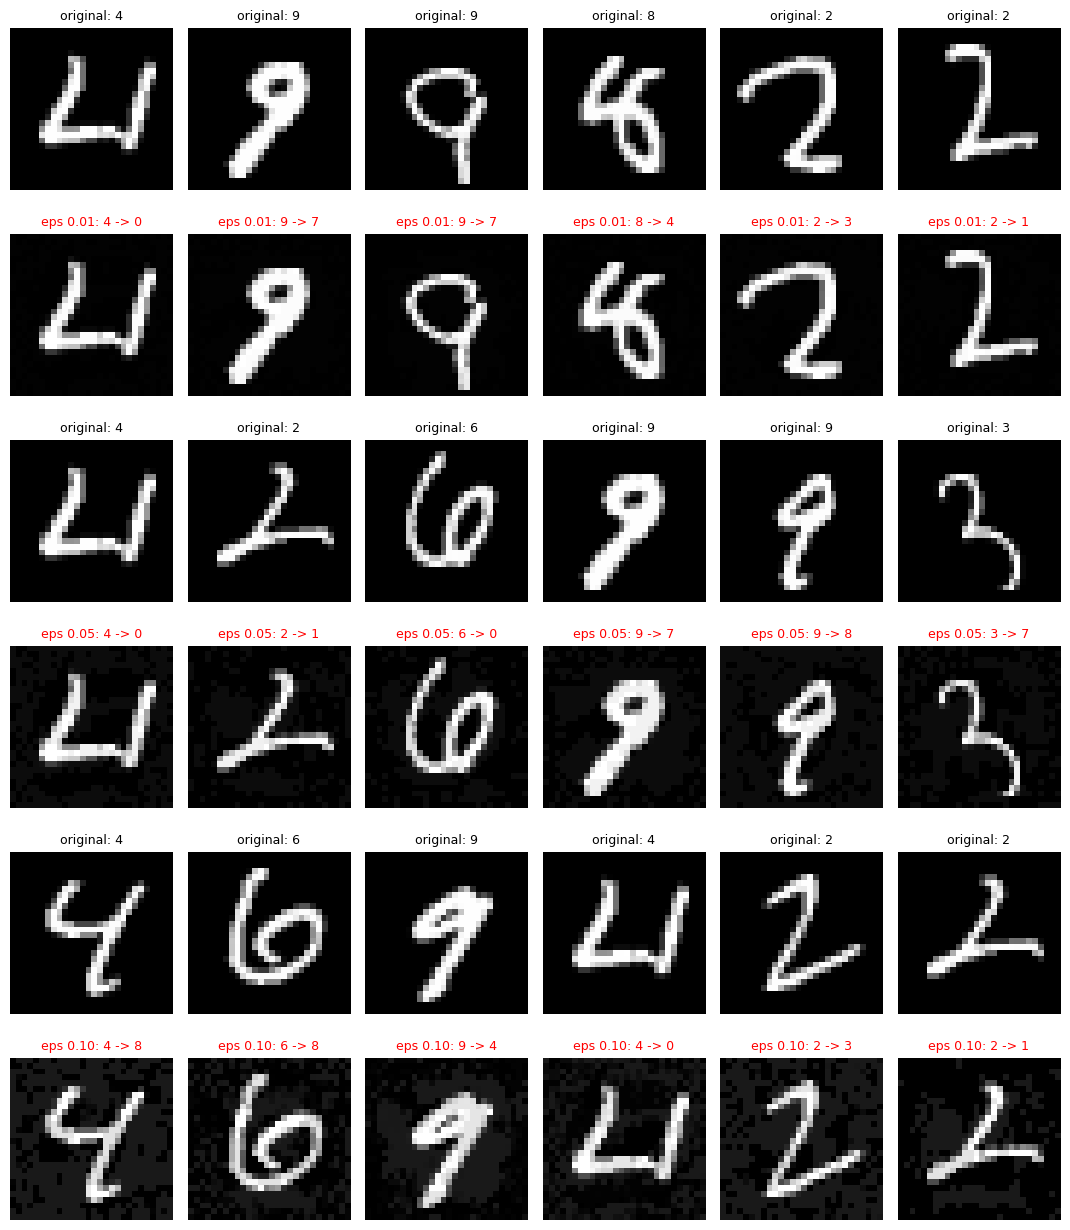

In [8]:
SHOW = [0, 4, 9]
N_COLS = 6

fig, axes = plt.subplots(2 * len(SHOW), N_COLS, figsize=(1.8 * N_COLS, 2.1 * 2 * len(SHOW)))
for row, k in enumerate(SHOW):
    for col in range(N_COLS):
        ax_o, ax_a = axes[2 * row, col], axes[2 * row + 1, col]
        ax_o.axis('off')
        ax_a.axis('off')
        if col >= len(examples[k]):
            continue
        x_o, x_a, y, p = examples[k][col]
        ax_o.imshow(x_o.squeeze().cpu(), cmap='gray', vmin=0, vmax=1)
        ax_o.set_title(f'original: {y.item()}', fontsize=9)
        ax_a.imshow(x_a.squeeze().cpu(), cmap='gray', vmin=0, vmax=1)
        ax_a.set_title(f'eps {epsilons[k]:.2f}: {y.item()} -> {p.item()}', fontsize=9, color='red')
plt.tight_layout()
plt.savefig('adv_examples.png', dpi=200)
plt.show()